# Phase 5 — Questionnaire Scoring (M-CHAT-R/F)

**Multimodal Autism Screening System — Phase 5 of 6**

| Item | Value |
|---|---|
| Instrument | M-CHAT-R (20 items) + optional Follow-Up (M-CHAT-R/F), March 2025 terminology update |
| Input | Parent answers: interactive prompts, Python dict, or CSV batch |
| Scoring | Official rule-based algorithm (no ML) |
| Output | `questionnaire_features.csv` — Q1–Q20 binaries + DSM-5/ICF domain subscores, ready for Phase 6 fusion |

**What this module adds beyond raw scoring**
- **DSM-5 mapping** — every item is tagged with the DSM-5 ASD criterion it probes (A1 social-emotional reciprocity · A2 nonverbal communication · A3 relationships · B1 stereotyped movements · B4 sensory reactivity).
- **ICF mapping** — every item is tagged with ICF functioning/disability codes (body functions + activities & participation).
- **Four risk-axis subscores** — questionnaire evidence is distributed across the project's four Phase-6 risk outputs (Social Communication, Attention Regulation, Speech & Language, Repetitive Behaviour).
- **Clinical override flag** — HIGH band (≥ 8) forces a referral recommendation independent of the ML pipeline.

> © 2009 Diana Robins, Deborah Fein, & Marianne Barton. Terminology update March 2025. The M-CHAT-R/F is free for clinical, research and educational use; items must be used in their entirety and unmodified. Screening result ≠ diagnosis — screen-positive children should be referred for diagnostic evaluation.

## 1 · Item bank with DSM-5 / ICF annotations

Each item carries: exact M-CHAT-R wording · `reverse` scoring flag (items 2, 5, 12 score on **YES**; all others on **NO**) · the psychological construct · DSM-5 criterion · ICF code(s) · the project risk axes it feeds.

In [ ]:
# ============================================================================
# M-CHAT-R item bank — wording verbatim from M-CHAT-R/F (March 2025 update)
# reverse=True  -> "YES" indicates elevated likelihood (items 2, 5, 12)
# reverse=False -> "NO"  indicates elevated likelihood (all other items)
# axes: SC = Social Communication | AR = Attention Regulation
#       SL = Speech & Language  | RB = Repetitive Behaviour
# ============================================================================

ITEMS = [
 dict(n=1,  reverse=False,
      text="If you point at something across the room, does your child look at it?",
      example="if you point at a toy or an animal, does your child look at the toy or animal?",
      construct="Responding to joint attention (gaze/point following)",
      dsm5="A2 — nonverbal communicative behaviours (joint attention)",
      icf="d110 Watching; d710 Basic interpersonal interactions",
      axes={"SC": 1.0, "AR": 0.5}),
 dict(n=2,  reverse=True,
      text="Have you ever wondered if your child might be deaf?",
      example="",
      construct="Inconsistent response to sound / social orienting (discriminant item)",
      dsm5="A2 — social orienting; possible B4 hypo-reactivity to auditory input",
      icf="b1560 Auditory perception; d115 Listening",
      axes={"SL": 0.5, "AR": 0.5}),
 dict(n=3,  reverse=False,
      text="Does your child play pretend or make-believe?",
      example="pretend to drink from an empty cup, pretend to talk on a phone, or pretend to feed a doll or stuffed animal",
      construct="Symbolic / pretend play",
      dsm5="A3 — developing & maintaining relationships (sharing imaginative play)",
      icf="d880 Engagement in play",
      axes={"SC": 1.0}),
 dict(n=4,  reverse=False,
      text="Does your child like climbing on things?",
      example="furniture, playground equipment, or stairs",
      construct="Gross-motor control item (not ASD-specific; low weight)",
      dsm5="— (control item)",
      icf="d455 Moving around",
      axes={}),
 dict(n=5,  reverse=True,
      text="Does your child make unusual finger movements near his or her eyes?",
      example="does your child wiggle his or her fingers close to his or her eyes?",
      construct="Motor stereotypy / visual self-stimulation",
      dsm5="B1 — stereotyped or repetitive motor movements; B4 — sensory interest",
      icf="b765 Involuntary movement functions; b1562 Visual perception",
      axes={"RB": 1.0}),
 dict(n=6,  reverse=False,
      text="Does your child point with one finger to ask for something or to get help?",
      example="pointing to a snack or toy that is out of reach",
      construct="Protoimperative pointing (requesting)",
      dsm5="A2 — nonverbal communication (gestures)",
      icf="d335 Producing nonverbal messages",
      axes={"SC": 0.5, "SL": 0.5}),
 dict(n=7,  reverse=False,
      text="Does your child point with one finger to show you something interesting?",
      example="pointing to an airplane in the sky or a big truck in the road",
      construct="Protodeclarative pointing / initiating joint attention",
      dsm5="A2 — joint attention; A1 — sharing interests",
      icf="d335 Producing nonverbal messages; d710 Basic interpersonal interactions",
      axes={"SC": 1.0}),
 dict(n=8,  reverse=False,
      text="Is your child interested in other children?",
      example="does your child watch other children, smile at them, or go to them?",
      construct="Peer interest",
      dsm5="A3 — developing & maintaining relationships (peer interest)",
      icf="d750 Informal social relationships; d710 Basic interpersonal interactions",
      axes={"SC": 1.0}),
 dict(n=9,  reverse=False,
      text="Does your child show you things by bringing them to you or holding them up for you to see — not to get help, but just to share?",
      example="showing you a flower, a stuffed animal, or a toy truck",
      construct="Sharing interest / showing objects",
      dsm5="A1 — social-emotional reciprocity (sharing interests)",
      icf="d710 Basic interpersonal interactions",
      axes={"SC": 1.0}),
 dict(n=10, reverse=False,
      text="Does your child respond when you call his or her name?",
      example="does he or she look up, talk or babble, or stop what he or she is doing when you call his or her name?",
      construct="Response to name (social orienting)",
      dsm5="A2 — social orienting / response to social bids",
      icf="d115 Listening; b1560 Auditory perception",
      axes={"AR": 1.0, "SC": 0.5, "SL": 0.5}),
 dict(n=11, reverse=False,
      text="When you smile at your child, does he or she smile back at you?",
      example="",
      construct="Social smile / reciprocity",
      dsm5="A1 — social-emotional reciprocity",
      icf="d710 Basic interpersonal interactions",
      axes={"SC": 1.0}),
 dict(n=12, reverse=True,
      text="Does your child get upset by everyday noises?",
      example="does your child scream or cry to noise such as a vacuum cleaner or loud music",
      construct="Auditory hyper-sensitivity",
      dsm5="B4 — hyper-reactivity to sensory input",
      icf="b1560 Auditory perception; b152 Emotional functions",
      axes={"RB": 1.0}),
 dict(n=13, reverse=False,
      text="Does your child walk?",
      example="",
      construct="Motor milestone control item (not ASD-specific)",
      dsm5="— (control item)",
      icf="d450 Walking",
      axes={}),
 dict(n=14, reverse=False,
      text="Does your child look you in the eye when you are talking to him or her, playing with him or her, or dressing him or her?",
      example="",
      construct="Eye contact during social interaction",
      dsm5="A2 — nonverbal communication (eye contact)",
      icf="d710 Basic interpersonal interactions; d335 Producing nonverbal messages",
      axes={"SC": 1.0, "AR": 0.5}),
 dict(n=15, reverse=False,
      text="Does your child try to copy what you do?",
      example="wave bye-bye, clap, make a funny noise when you do",
      construct="Imitation",
      dsm5="A2 — imitation supporting social communication",
      icf="d130 Copying; d155 Acquiring skills",
      axes={"SC": 0.5, "SL": 0.5}),
 dict(n=16, reverse=False,
      text="If you turn your head to look at something, does your child look around to see what you are looking at?",
      example="",
      construct="Gaze following (responding to joint attention)",
      dsm5="A2 — joint attention",
      icf="d110 Watching; d710 Basic interpersonal interactions",
      axes={"AR": 1.0, "SC": 0.5}),
 dict(n=17, reverse=False,
      text="Does your child try to get you to watch him or her?",
      example="does your child look at you for praise, or say \u201clook\u201d or \u201cwatch me\u201d?",
      construct="Bids for social attention",
      dsm5="A1 — social-emotional reciprocity (initiating social contact)",
      icf="d710 Basic interpersonal interactions",
      axes={"SC": 1.0}),
 dict(n=18, reverse=False,
      text="Does your child understand when you tell him or her to do something?",
      example="if you don\u2019t point, can your child understand \u201cput the book on the chair\u201d or \u201cbring me the blanket\u201d?",
      construct="Receptive language",
      dsm5="A2 — integration of verbal communication (receptive language)",
      icf="d310 Communicating with – receiving spoken messages; b1670 Reception of language",
      axes={"SL": 1.0, "AR": 0.5}),
 dict(n=19, reverse=False,
      text="If something new happens, does your child look at your face to see how you feel about it?",
      example="if he or she hears a strange or funny noise, or sees a new toy, will he or she look at your face?",
      construct="Social referencing",
      dsm5="A1 — social-emotional reciprocity (social referencing)",
      icf="d710 Basic interpersonal interactions",
      axes={"SC": 0.5, "AR": 0.5}),
 dict(n=20, reverse=False,
      text="Does your child like movement activities?",
      example="being swung or bounced on your knee",
      construct="Enjoyment of social-physical play",
      dsm5="A1 — social-emotional reciprocity in play",
      icf="d880 Engagement in play; d760 Family relationships",
      axes={"SC": 0.5}),
]

assert len(ITEMS) == 20
assert [i["n"] for i in ITEMS] == list(range(1, 21))
assert [i["n"] for i in ITEMS if i["reverse"]] == [2, 5, 12], "reverse-scored items must be 2, 5, 12"
print("Item bank OK: 20 items, reverse-scored items = [2, 5, 12] (matches official algorithm)")

Item bank OK: 20 items, reverse-scored items = [2, 5, 12] (matches official algorithm)


## 2 · Enter answers

Three ways — pick one:

- **A · Interactive** (default): run the cell and answer `y`/`n` for each question.
- **B · Dict**: fill in `ANSWERS` directly, e.g. `{1:"yes", 2:"no", ...}`.
- **C · CSV batch** (Section 6): a file with one column per question, one row per child.

In [ ]:
# ---------------- Choose input mode ----------------
MODE = "A"            # "A" = interactive prompts | "B" = ANSWERS dict below
ANSWERS = {           # used when MODE = "B"   (1="yes"/"no", ...)
    1:"yes", 2:"no", 3:"yes", 4:"yes", 5:"no", 6:"yes", 7:"no", 8:"yes", 9:"yes", 10:"yes",
    11:"yes", 12:"yes", 13:"yes", 14:"no", 15:"yes", 16:"yes", 17:"yes", 18:"yes", 19:"yes", 20:"yes",
}
CHILD_ID = "child_001"
# ----------------------------------------------------

def normalize(ans):
    a = str(ans).strip().lower()
    if a in ("y","yes","1","true"):  return "yes"
    if a in ("n","no","0","false"):  return "no"
    raise ValueError(f"Answer must be yes/no, got: {ans!r}")

if MODE == "A":
    print("Answer about how your child USUALLY behaves. Type y or n.\n")
    ANSWERS = {}
    for it in ITEMS:
        ex = f"  (e.g., {it['example']})" if it["example"] else ""
        while True:
            a = input(f"Q{it['n']:>2}. {it['text']}{ex}  [y/n]: ")
            try:
                ANSWERS[it["n"]] = normalize(a); break
            except ValueError as e:
                print("   ", e)
elif MODE == "B":
    ANSWERS = {int(k): normalize(v) for k, v in ANSWERS.items()}
    assert set(ANSWERS) == set(range(1, 21)), "ANSWERS must cover all 20 items"
print("\nAnswers recorded:", {k: ("Y" if v=="yes" else "N") for k,v in sorted(ANSWERS.items())})

Answer about how your child USUALLY behaves. Type y or n.

Q 1. If you point at something across the room, does your child look at it?  (e.g., if you point at a toy or an animal, does your child look at the toy or animal?)  [y/n]: y
Q 2. Have you ever wondered if your child might be deaf?  [y/n]: n
Q 3. Does your child play pretend or make-believe?  (e.g., pretend to drink from an empty cup, pretend to talk on a phone, or pretend to feed a doll or stuffed animal)  [y/n]: y
Q 4. Does your child like climbing on things?  (e.g., furniture, playground equipment, or stairs)  [y/n]: y
Q 5. Does your child make unusual finger movements near his or her eyes?  (e.g., does your child wiggle his or her fingers close to his or her eyes?)  [y/n]: y
Q 6. Does your child point with one finger to ask for something or to get help?  (e.g., pointing to a snack or toy that is out of reach)  [y/n]: y
Q 7. Does your child point with one finger to show you something interesting?  (e.g., pointing to an airpla

## 3 · Official M-CHAT-R scoring

For all items **except 2, 5 and 12**, "NO" indicates elevated likelihood; for items **2, 5, 12**, "YES" indicates elevated likelihood. One point per at-risk item.

| Total | Band | Official action |
|---|---|---|
| 0–2 | **LOW** | Rescreen after 24 months if younger; no action unless surveillance indicates concern |
| 3–7 | **MODERATE** | Administer Follow-Up (M-CHAT-R/F); refer if Follow-Up score ≥ 2 |
| 8–20 | **HIGH** | Acceptable to bypass Follow-Up and refer immediately |

In [ ]:
import pandas as pd

def score_item(item, answer):
    at_risk = (answer == "yes") if item["reverse"] else (answer == "no")
    return int(at_risk)

def score_mchatr(answers):
    rows, total = [], 0
    for it in ITEMS:
        ans = normalize(answers[it["n"]])
        s = score_item(it, ans)
        total += s
        rows.append(dict(item=it["n"], answer=ans, at_risk=s,
                         construct=it["construct"], dsm5=it["dsm5"], icf=it["icf"]))
    if total <= 2:   band, action = "LOW", "No action required; rescreen after 2nd birthday if < 24 months."
    elif total <= 7: band, action = "MODERATE", "Administer M-CHAT-R/F Follow-Up; refer for diagnostic + early-intervention evaluation if Follow-Up >= 2."
    else:            band, action = "HIGH", "Refer immediately for diagnostic + early-intervention evaluation (Follow-Up may be bypassed)."
    return total, band, action, pd.DataFrame(rows)

TOTAL, BAND, ACTION, item_df = score_mchatr(ANSWERS)
print(f"M-CHAT-R total : {TOTAL} / 20")
print(f"Band           : {BAND}")
print(f"Action         : {ACTION}")
print(f"Clinical override flag (feeds Phase 6): {'REFER' if TOTAL >= 8 else 'none'}")
display(item_df[item_df.at_risk == 1] if (item_df.at_risk == 1).any() else item_df.head(0))

M-CHAT-R total : 1 / 20
Band           : LOW
Action         : No action required; rescreen after 2nd birthday if < 24 months.
Clinical override flag (feeds Phase 6): none


,item,answer,at_risk,construct,dsm5,icf
4,5,yes,1,Motor stereotypy / visual self-stimulation,B1 — stereotyped or repetitive motor movements...,b765 Involuntary movement functions; b1562 Vis...


## 4 · DSM-5 & ICF domain analysis

The raw total treats every item equally. This section breaks the at-risk responses down by **DSM-5 criterion** and by the project's **four risk axes**, so the questionnaire shapes *which* risk categories are elevated in Phase 6 — not just *whether* risk is elevated.

Axis subscore = Σ(item at-risk × item's axis weight). Percentages are relative to each axis's maximum attainable subscore.

— Project risk axes (questionnaire contribution) —


,axis,subscore,max,pct
0,Social Communication Risk,0.0,11.0,0.0
1,Attention Regulation Risk,0.0,4.5,0.0
2,Speech & Language Risk,0.0,3.0,0.0
3,Repetitive Behaviour Risk,1.0,2.0,50.0


— DSM-5 criteria coverage —


,dsm5_criterion,items,at_risk_items,of
0,A1,"[9, 11, 17, 19, 20]",0,5
1,A2,"[1, 2, 6, 7, 10, 14, 15, 16, 18]",0,9
2,A3,"[3, 8]",0,2
3,B1,[5],1,1
4,B4,[12],0,1


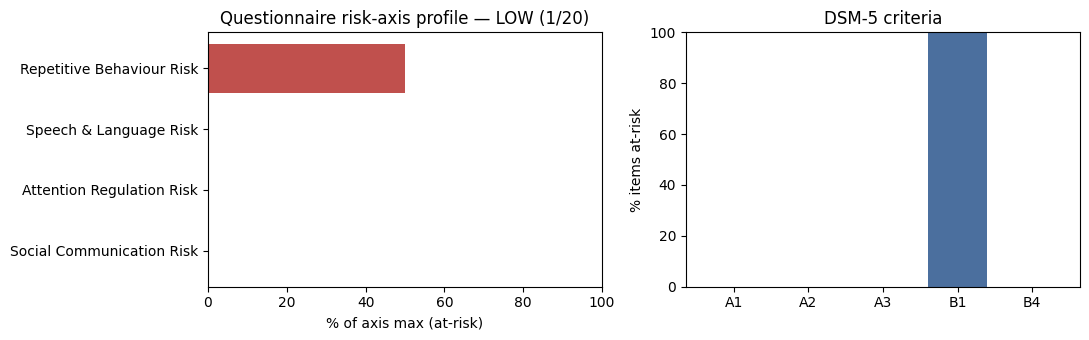

In [ ]:
import numpy as np

AXES = {"SC": "Social Communication Risk", "AR": "Attention Regulation Risk",
        "SL": "Speech & Language Risk",   "RB": "Repetitive Behaviour Risk"}

def domain_analysis(item_df):
    # --- project risk axes ---
    axis_max = {a: sum(it["axes"].get(a, 0) for it in ITEMS) for a in AXES}
    axis_score = {a: 0.0 for a in AXES}
    for _, r in item_df.iterrows():
        it = ITEMS[int(r["item"]) - 1]
        for a, w in it["axes"].items():
            axis_score[a] += r["at_risk"] * w
    axis_rows = [dict(axis=AXES[a], subscore=axis_score[a],
                      max=axis_max[a],
                      pct=round(100 * axis_score[a] / axis_max[a], 1) if axis_max[a] else 0.0)
                 for a in AXES]

    # --- DSM-5 criterion groups ---
    def group(letter):
        ns = [it["n"] for it in ITEMS if it["dsm5"].startswith(letter)]
        hit = int(item_df[(item_df.item.isin(ns)) & (item_df.at_risk == 1)].shape[0])
        return dict(dsm5_criterion=letter, items=ns, at_risk_items=hit, of=len(ns))
    dsm_rows = [group(x) for x in ("A1", "A2", "A3", "B1", "B4")]

    return pd.DataFrame(axis_rows), pd.DataFrame(dsm_rows), axis_score

axis_df, dsm_df, AXIS_SCORES = domain_analysis(item_df)

print("— Project risk axes (questionnaire contribution) —")
display(axis_df)
print("— DSM-5 criteria coverage —")
display(dsm_df)

# quick visualization
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].barh(axis_df["axis"], axis_df["pct"], color="#c0504d")
ax[0].set_xlim(0, 100); ax[0].set_xlabel("% of axis max (at-risk)")
ax[0].set_title(f"Questionnaire risk-axis profile — {BAND} ({TOTAL}/20)")
dsm_plot = dsm_df.copy(); dsm_plot["pct"] = 100 * dsm_plot["at_risk_items"] / dsm_plot["of"]
ax[1].bar(dsm_plot["dsm5_criterion"], dsm_plot["pct"], color="#4b6f9e")
ax[1].set_ylim(0, 100); ax[1].set_ylabel("% items at-risk"); ax[1].set_title("DSM-5 criteria")
plt.tight_layout(); plt.show()

## 5 · Optional — M-CHAT-R/F Follow-Up (MODERATE band only)

If the total is 3–7, the official protocol administers the Follow-Up interview **only for the at-risk items**, re-scoring each as 0/1. If the Follow-Up score is ≥ 2, the child has screened positive. Enter the post-interview 0/1 values below (the full flowchart interview is in the official M-CHAT-R/F document).

In [ ]:
FOLLOWUP_SCORES = {}   # e.g. {7: 1, 14: 0} — only for items that scored at-risk, after the interview

followup_result = None
if BAND == "MODERATE":
    atrisk = [int(r["item"]) for _, r in item_df.iterrows() if r["at_risk"] == 1]
    if not FOLLOWUP_SCORES:
        print(f"At-risk items to administer in the Follow-Up interview: {atrisk}")
        print("Fill FOLLOWUP_SCORES after the interview and re-run this cell.")
    else:
        assert set(FOLLOWUP_SCORES) <= set(atrisk), "Follow-Up only applies to at-risk items"
        fu_total = sum(int(v) for v in FOLLOWUP_SCORES.values())
        followup_result = "POSITIVE — refer for diagnostic evaluation" if fu_total >= 2 else "NEGATIVE — rescreen at future visits"
        print(f"Follow-Up score: {fu_total} on administered items → {followup_result}")
else:
    print(f"Band is {BAND} — Follow-Up {'not required (refer immediately)' if BAND=='HIGH' else 'not required'}.")

## 6 · Batch mode — score a CSV of many children

CSV format: one row per child, columns `child_id, Q1, Q2, ..., Q20` with yes/no (or 1/0) answers. A template is generated for you.

In [ ]:
BATCH_CSV = None   # e.g. "/content/drive/MyDrive/mchat_answers.csv"

if BATCH_CSV:
    raw = pd.read_csv(BATCH_CSV)
    out_rows = []
    for _, r in raw.iterrows():
        answers = {i: r[f"Q{i}"] for i in range(1, 21)}
        total, band, action, idf = score_mchatr(answers)
        _, _, ax_scores = domain_analysis(idf)
        row = {"child_id": r.get("child_id", f"row_{_}"), "mchatr_total": total, "band": band}
        row.update({f"Q{i}": score_item(ITEMS[i-1], normalize(answers[i])) for i in range(1, 21)})
        row.update({f"q_axis_{a.lower()}": ax_scores[a] for a in AXES})
        out_rows.append(row)
    batch_df = pd.DataFrame(out_rows)
    batch_df.to_csv("questionnaire_features_batch.csv", index=False)
    print(f"Scored {len(batch_df)} children → questionnaire_features_batch.csv")
    display(batch_df)
else:
    cols = ["child_id"] + [f"Q{i}" for i in range(1, 21)]
    pd.DataFrame(columns=cols).to_csv("mchat_template.csv", index=False)
    print("Template written → mchat_template.csv  (set BATCH_CSV to your filled file and re-run)")

## 7 · Export fusion-ready features → `questionnaire_features.csv`

Per child: 20 binary indicators (as specified in the report) **plus** total score, band, clinical override flag and the four axis subscores that carry the questionnaire's domain-level evidence into Phase 6.

In [ ]:
fusion_row = {"child_id": CHILD_ID,
              "mchatr_total": TOTAL, "mchatr_band": BAND,
              "mchatr_refer_override": int(TOTAL >= 8)}
if followup_result:
    fusion_row["mchatr_followup"] = followup_result
for i in range(1, 21):
    fusion_row[f"Q{i}"] = int(item_df.loc[item_df.item == i, "at_risk"].iloc[0])
for a in AXES:
    fusion_row[f"q_axis_{a.lower()}"] = AXIS_SCORES[a]

qdf = pd.DataFrame([fusion_row])
qdf.to_csv("questionnaire_features.csv", index=False)
print("Saved → questionnaire_features.csv")
display(qdf.T)
try:
    from google.colab import files; files.download("questionnaire_features.csv")
except Exception:
    pass

## 8 · How Phase 6 should weight the questionnaire (recommended)

The M-CHAT-R is the only clinically validated instrument in the pipeline; the ML modalities are experimental signals. To give it a **greater role** in the final risk predictions:

1. **Feature weighting in XGBoost** — when training, pass `sample_weight` or scale the questionnaire block (`Q1..Q20`, `q_axis_*`, `mchatr_total`) by a factor **W ≈ 2** relative to ML-modality features, so a questionnaire signal counts about twice as much as any single audio/video feature.
2. **Score blending** — combine the XGBoost probability with the normalised questionnaire score:

   `final_risk = 0.6 × xgboost_probability + 0.4 × (mchatr_total / 20)`

3. **Hard clinical override** — if `mchatr_refer_override == 1` (total ≥ 8), always surface "refer for diagnostic evaluation", regardless of the model output.

```python
# Phase-6 sketch
W_QUESTIONNAIRE = 2.0
X_train[q_cols] = X_train[q_cols] * W_QUESTIONNAIRE      # boost questionnaire block
model.fit(X_train, y_train)
final = 0.6 * model.predict_proba(X_test)[:, 1] + 0.4 * (X_test_raw["mchatr_total"] / 20)
refer = (X_test_raw["mchatr_refer_override"] == 1) | (final > THRESHOLD)
```

> ⚠️ This system is a screening and decision-support aid. M-CHAT-R has a high false-positive rate by design (sensitivity is prioritised); screen-positive results warrant professional evaluation, not conclusions.